<a href="https://colab.research.google.com/github/Jashan-Khangura/learn-pytorch/blob/main/pytorch_tabular_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opendatasets legacy-cgi
import opendatasets as od

od.download("https://kaggle.com/datasets/mssmartypants/rice-type-classification")

In [ ]:
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [ ]:
data_df = pd.read_csv("/content/rice-type-classification/riceClassification.csv")
data_df.dropna(inplace=True)
data_df.drop(['id'], axis=1, inplace=True)
print(data_df.shape)
print(data_df['Class'].unique())
data_df.head()

(18185, 11)
[1 0]


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


###Next:  Normalizing the Dataset
We will normalize each feature column to have a maximum value of 1. This prevents large input values from overwhelming the neural network weights and makes training computationally stable and fast.

In [ ]:
original_df = data_df.copy()

for column in data_df.columns:
  data_df[column] = data_df[column]/data_df[column].abs().max()

data_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,0.444368,0.503404,0.775435,0.744658,0.424873,0.666610,0.741661,0.537029,0.844997,0.368316,1.0
1,0.281293,0.407681,0.622653,0.750489,0.273892,0.530370,0.804230,0.409661,0.919215,0.371471,1.0
2,0.298531,0.416421,0.630442,0.756341,0.284520,0.546380,0.856278,0.412994,0.959862,0.374747,1.0
3,0.300979,0.420463,0.629049,0.764024,0.286791,0.548616,0.883772,0.414262,0.961818,0.379222,1.0
4,0.361704,0.464626,0.682901,0.775033,0.345385,0.601418,0.867808,0.452954,0.966836,0.386007,1.0


In [ ]:
X = np.array(data_df.iloc[:, :-1])
Y = np.array(data_df.iloc[:, -1])

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3)

X_test, X_val, Y_test, Y_val = train_test_split(X_test, Y_test, test_size=0.5)

print(X_train.shape, X_test.shape, X_val.shape)

(12729, 10) (2728, 10) (2728, 10)


In [ ]:
class dataset(Dataset):
  def __init__(self, X, Y):
    self.X = torch.tensor(X, dtype=torch.float32).to(device)
    self.Y = torch.tensor(Y, dtype=torch.float32).to(device)

  def __len__(self):
    return len(self.X)

  def __getitem__(self, index):
    return self.X[index], self.Y[index]

In [ ]:
training_data = dataset(X_train, Y_train)
validation_data = dataset(X_val, Y_val)
testing_data = dataset(X_test, Y_test)

training_dataloader = DataLoader(training_data, batch_size=32, shuffle=True)
validation_dataloader = DataLoader(validation_data, batch_size=32, shuffle=True)
testing_dataloader = DataLoader(testing_data, batch_size=32, shuffle=True)

In [ ]:
HIDDEN_NEURONS = 10

class MyModel(nn.Module):
  def __init__(self):
    super(MyModel, self).__init__()

    self.input_layer = nn.Linear(X.shape[1], HIDDEN_NEURONS)
    self.linear = nn.Linear(HIDDEN_NEURONS, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    x = self.input_layer(x)
    x = self.linear(x)
    x = self.sigmoid(x)
    return x

model = MyModel().to(device)

In [ ]:
summary(model, (X.shape[1],))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 10]             110
            Linear-2                    [-1, 1]              11
           Sigmoid-3                    [-1, 1]               0
Total params: 121
Trainable params: 121
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [ ]:
criterion = nn.BCELoss()
optimizer = Adam(model.parameters(), lr=0.001)

In [ ]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_accuracy_train_plot = []
total_accuracy_validation_plot = []

for epoch in range(10):
  total_loss_train = 0
  total_loss_validation = 0
  total_accuracy_train = 0
  total_accuracy_validation = 0

  for data in training_dataloader:
    input, labels = data

    prediction = model(input).squeeze(1)
    loss = criterion(prediction, labels)
    total_loss_train += loss.item()

    accuracy = (prediction.round() == labels).sum().item()
    total_accuracy_train += accuracy

    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

  with torch.no_grad():
    for data in validation_dataloader:
      input, labels = data

      prediction = model(input).squeeze(1)
      loss = criterion(prediction, labels)
      total_loss_validation += loss.item()

      accuracy = (prediction.round() == labels).sum().item()
      total_accuracy_validation += accuracy

  total_loss_train_plot.append(round(total_loss_train/1000, 4))
  total_loss_validation_plot.append(round(total_loss_validation/1000, 4))

  total_accuracy_train_plot.append(round(total_accuracy_train/training_data.__len__() * 100, 4))
  total_accuracy_validation_plot.append(round(total_accuracy_validation/validation_data.__len__() * 100, 4))

  print(f'''Epoch no. {epoch+1}
        Training loss {round(total_loss_train/1000, 4)} Training accuracy {round(total_accuracy_train/training_data.__len__() * 100, 4)}
        Validation loss {round(total_loss_validation/1000, 4)} Validation accuracy {round(total_accuracy_validation/validation_data.__len__() * 100, 4)}''')
  print("-"*50)

Epoch no. 1
        Training loss 0.0173 Training accuracy 98.6016
        Validation loss 0.0039 Validation accuracy 98.607
--------------------------------------------------
Epoch no. 2
        Training loss 0.017 Training accuracy 98.6723
        Validation loss 0.0039 Validation accuracy 98.4604
--------------------------------------------------
Epoch no. 3
        Training loss 0.0169 Training accuracy 98.6173
        Validation loss 0.0039 Validation accuracy 98.3504
--------------------------------------------------
Epoch no. 4
        Training loss 0.0166 Training accuracy 98.6409
        Validation loss 0.0038 Validation accuracy 98.5337
--------------------------------------------------
Epoch no. 5
        Training loss 0.0164 Training accuracy 98.6645
        Validation loss 0.0038 Validation accuracy 98.5337
--------------------------------------------------
Epoch no. 6
        Training loss 0.0165 Training accuracy 98.6802
        Validation loss 0.0038 Validation accuracy

In [ ]:
with torch.no_grad():
  total_accuracy_test = 0

  for data in testing_dataloader:
    input, labels = data

    prediction = model(input).squeeze(1)
    accuracy = (prediction.round() == labels).sum().item()
    total_accuracy_test += accuracy

  print(f"Accuracy {round(total_accuracy_test/testing_data.__len__() * 100, 4)}")

Accuracy 98.9736


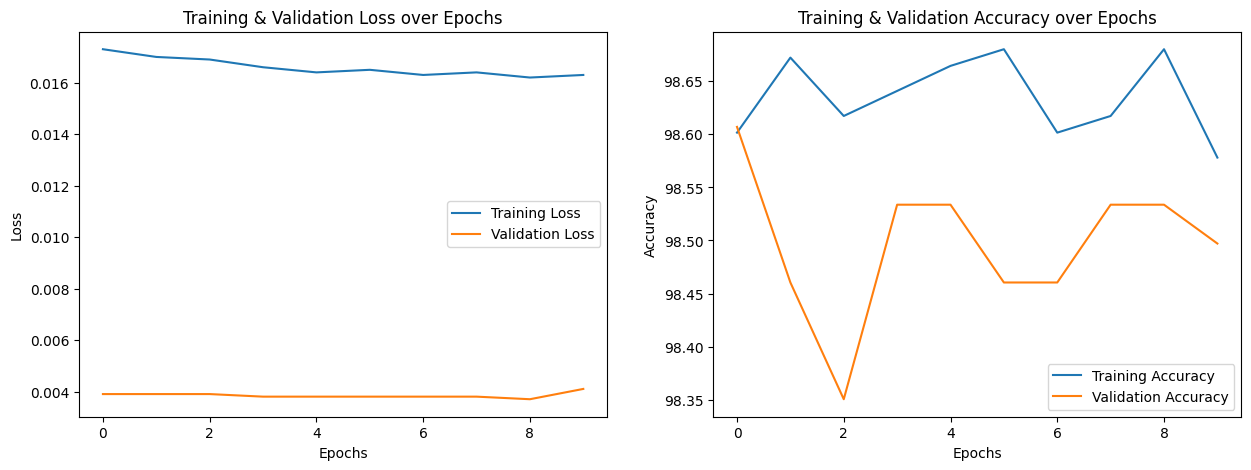

In [ ]:
fig, axis = plt.subplots(nrows=1, ncols=2, figsize=(15,5))

axis[0].plot(total_loss_train_plot, label="Training Loss")
axis[0].plot(total_loss_validation_plot, label="Validation Loss")
axis[0].set_title("Training & Validation Loss over Epochs")
axis[0].set_xlabel("Epochs")
axis[0].set_ylabel("Loss")
axis[0].legend()

axis[1].plot(total_accuracy_train_plot, label="Training Accuracy")
axis[1].plot(total_accuracy_validation_plot, label="Validation Accuracy")
axis[1].set_title("Training & Validation Accuracy over Epochs")
axis[1].set_xlabel("Epochs")
axis[1].set_ylabel("Accuracy")
axis[1].legend()

plt.show()